# 大模型微调 10：BERT + P-Tuning 小样本文本分类

本篇整理 `10-附属资料`、`10-课件` 和 `10-代码/P-Tuning`。课程以电商用户评论为背景，使用 BERT 的 Masked Language Model 能力，把人工 Prompt 替换成可学习的连续软模板，用少量标注样本完成评论分类。

## 学习目标

- 理解 P-Tuning 怎样用可学习的伪 token 代替手工模板；
- 理解训练数据如何插入 `[MASK]`、软模板 token 和原始评论；
- 读懂 Verbalizer、MLM loss、指标评估、训练验证和推理代码；
- 能区分当前代码真正训练的参数与课程中对 P-Tuning 的概念描述；
- 能根据日志、验证集标签和数据量判断模型结果。

本篇是 10 号资料的独立笔记。09 篇的 PET 使用自然语言硬模板；本篇把模板位置换成 `[unused1]` 等可训练 embedding，其他数据与 Verbalizer 思路仍然相连。

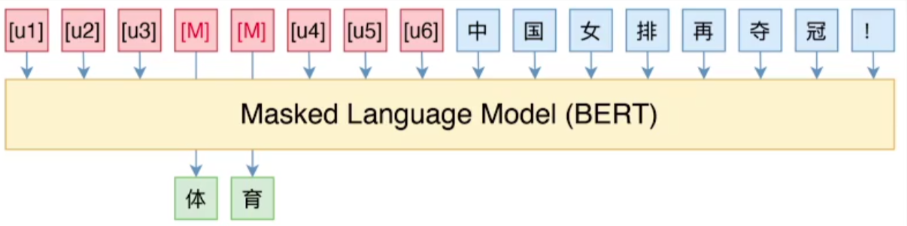

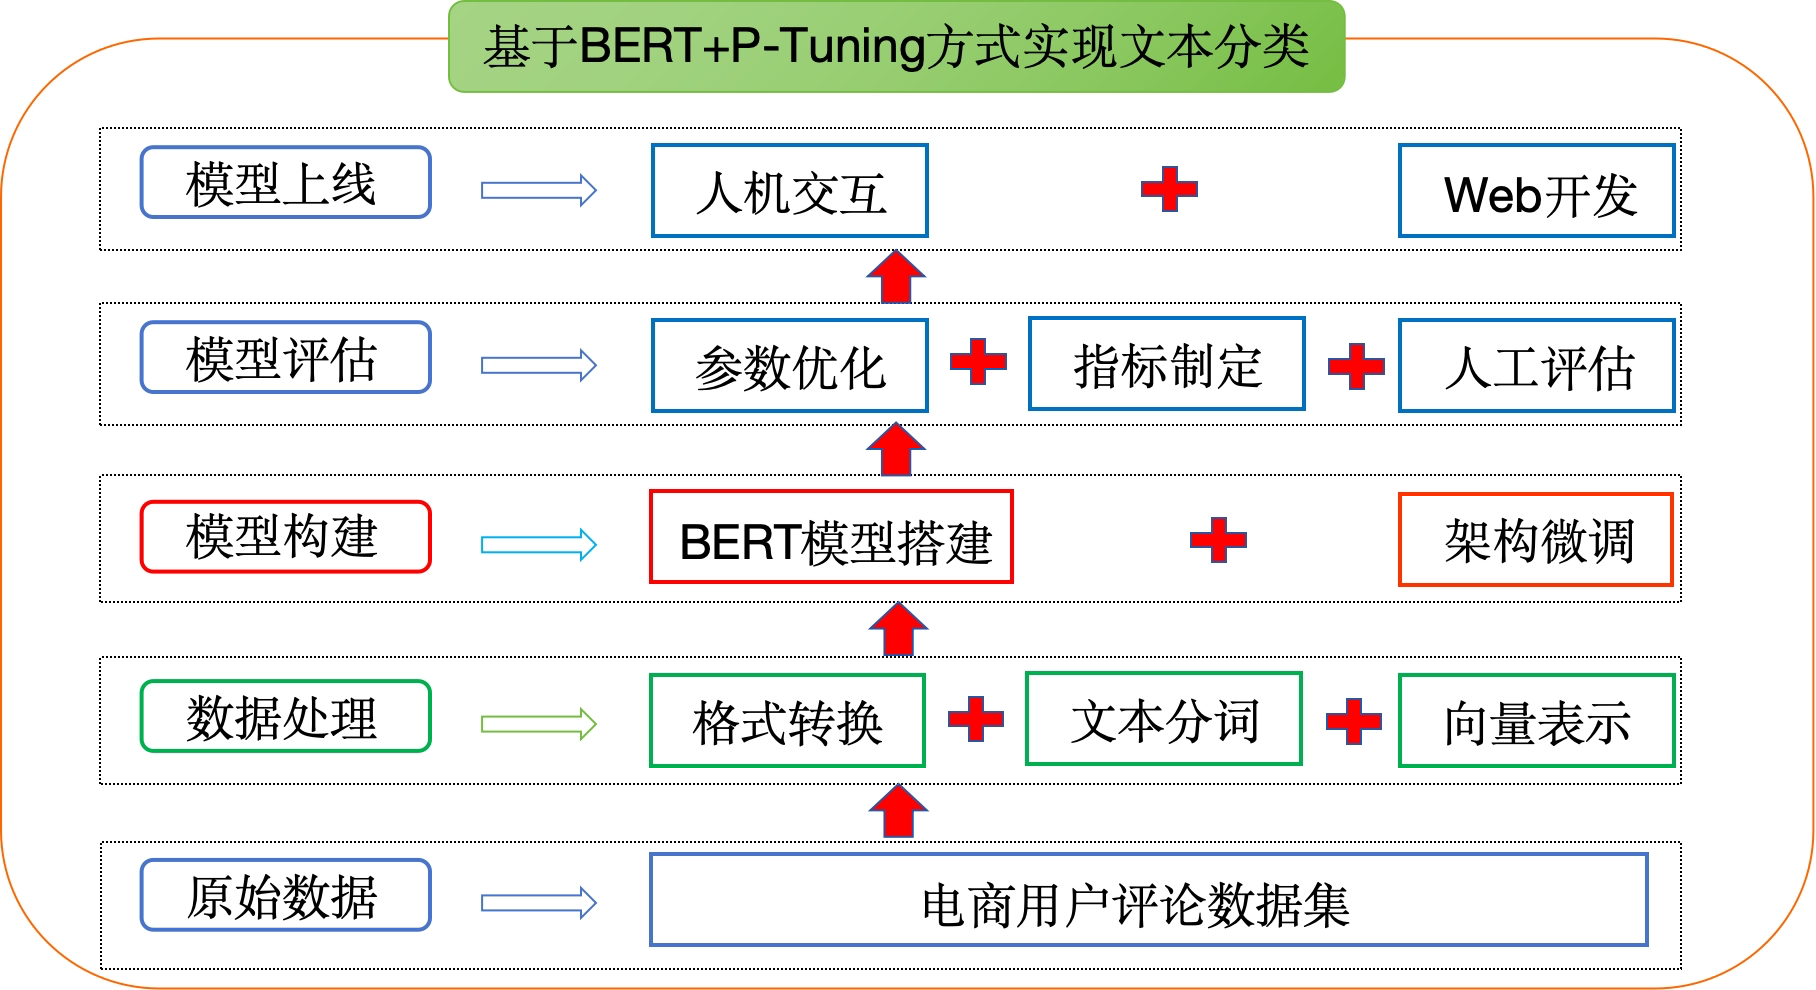

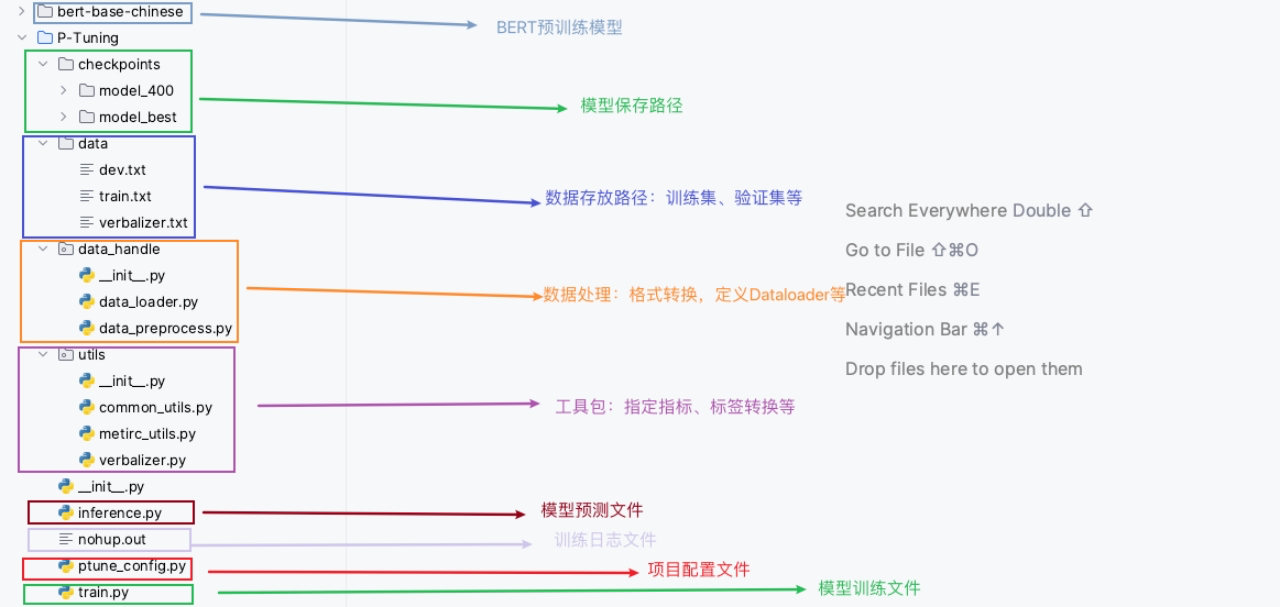

## 一、为什么需要 P-Tuning

文本分类常用于舆情监测、情感分析、商品评论分析等任务。Text-CNN、Text-RNN 和 BERT Fine-Tuning 往往依赖较多标注数据；领域数据不足且标注成本高时，模型容易过拟合。

PET 用人工自然语言模板解决了部分少样本问题，但模板措辞会影响结果。P-Tuning（Pattern-Tuning）把模板变成连续空间中的可学习向量：不再手工设计“这是一条[MASK]评论”这样的自然语言句子，而是学习一串伪 token embedding，再把 `[MASK]` 和原始文本送进预训练模型。

示例：

```text
原始文本：中国女排再夺冠！
软模板：[u1] [u2] … [MASK] … [un]
类别：体育 / 财经 / 时政 / 军事
```

模型仍在 `[MASK]` 位置预测标签词，但前面的 `[u1]...[un]` 不需要具备自然语言含义，它们的向量通过任务损失更新。

### 1.1 P-Tuning 的优点和边界

**优点**：模板参数可以全局优化，减少人工模板措辞带来的不稳定；在标注数据较少时，可以继续利用 BERT 的预训练语言知识。

**边界**：类别非常多时，`[MASK]` 的词汇预测难度会升高；蕴含等需要同时比较两句话逻辑关系的任务，不一定适合直接转成一个模板中的标签词预测。

课程实现的是一个单句、多类别电商评论任务，标签词长度固定为最多两个 token，适合当前的 `mask_positions` 和 MLM loss 代码。

## 二、项目数据与标签映射

代码路径为 `10-代码/P-Tuning/data`，包含：

| 文件 | 内容 | 资料中的数量 |
| --- | --- | ---: |
| `train.txt` | 每行 `label<TAB>评论` | 63 条 |
| `dev.txt` | 每行 `label<TAB>评论` | 课件约 590 条，PDF 记 417 条 |
| `verbalizer.txt` | 主标签到标签预测词的映射 | 10 个类别 |

当前下载版 `train.txt` 为 63 行，`dev.txt` 实际为 590 行；课程不同资料的统计口径存在差异，写笔记时以文件实际内容为准。

训练样本示例：

```text
水果	脆脆的，甜味可以，可能时间有点长了，水分不是很足。
平板	华为机器肯定不错，但第一次碰上京东最糟糕的服务，以后不想到京东购物了。
书籍	为什么不认真的检查一下，发这么一本脏脏的书给顾客呢！
```

标签与文本之间必须使用一个 tab。评论中可以包含空格和标点，但不能靠空格替代字段分隔。

### 2.1 Verbalizer：为什么不直接预测主标签

把“体育”直接作为 `[MASK]` 的预测词未必自然。可以把主标签映射到多个容易预测的子标签，例如：

```text
体育	足球,篮球,网球,棒球,乒乓,体育
水果	苹果,香蕉,橘子
```

训练时，一个主标签对应的每个子标签都会参与 MLM 损失；推理时，模型预测到任意子标签，再还原为主标签。当前下载版 `verbalizer.txt` 使用 10 个一对一映射：电脑、水果、平板、衣服、酒店、洗浴、书籍、蒙牛、手机、电器。

源码：`10-代码/P-Tuning/data/verbalizer.txt`。

```text
电脑	电脑
水果	水果
平板	平板
衣服	衣服
酒店	酒店
洗浴	洗浴
书籍	书籍
蒙牛	蒙牛
手机	手机
电器	电器
```

## 三、配置类与运行参数

`ptune_config.py` 统一管理设备、BERT 路径、训练/验证文件、Verbalizer、序列长度、软模板长度、训练轮数和 checkpoint 保存目录。关键默认值：

| 参数 | 默认值 | 作用 |
| --- | ---: | --- |
| `max_seq_len` | 512 | tokenizer 初始截断长度和最终输入长度上限 |
| `batch_size` | 8 | DataLoader 批大小 |
| `learning_rate` | `5e-5` | AdamW 学习率 |
| `p_embedding_num` | 6 | 伪 token 数量 |
| `max_label_len` | 2 | `[MASK]` 数量和标签 token 最大长度 |
| `epochs` | 50 | 训练轮数 |
| `logging_steps` | 10 | 训练日志间隔 |
| `valid_steps` | 20 | 验证与保存间隔 |
| `warmup_ratio` | 0.06 | warmup 步数占总步数的比例 |

下载版配置默认使用 `mps:0` 和作者机器的绝对路径；Windows 复现需要改为 `cuda:0` 或 `cpu`，并替换所有路径。课程的课件示例改用了相对路径，但代码文件本身仍保留作者的绝对路径。

源码：`10-代码/P-Tuning/ptune_config.py`。

```python
# coding:utf-8
import torch


class ProjectConfig(object):
    def __init__(self):
        # self.device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
        self.device = 'mps:0'
        self.pre_model = '/Users/ligang/PycharmProjects/llm/prompt_tasks/bert-base-chinese'
        self.train_path = '/Users/ligang/PycharmProjects/llm/prompt_tasks/P-Tuning/data/train.txt'
        self.dev_path = '/Users/ligang/PycharmProjects/llm/prompt_tasks/P-Tuning/data/dev.txt'
        self.verbalizer = '/Users/ligang/PycharmProjects/llm/prompt_tasks/P-Tuning/data/verbalizer.txt'
        self.max_seq_len = 512
        self.batch_size = 8
        self.learning_rate = 5e-5
        # 权重衰减系数
        self.weight_decay = 0
        # 学习率预热的系数
        self.warmup_ratio = 0.06
        # 伪token的个数
        self.p_embedding_num = 6
        self.max_label_len = 2
        self.epochs = 50
        self.logging_steps = 10
        self.valid_steps = 20
        self.save_dir = '/Users/ligang/PycharmProjects/llm/prompt_tasks/P-Tuning/checkpoints'


if __name__ == '__main__':
    pc = ProjectConfig()
    print(pc.verbalizer)
```

## 四、数据预处理：构造软模板输入

`data_handle/data_preprocess.py` 的 `convert_example()` 是整个 P-Tuning 数据管道的核心。它接收 `datasets` 的批量字典，返回模型需要的 `input_ids`、`attention_mask`、`mask_positions`、`mask_labels` 和可选的 `token_type_ids`。

### 4.1 输入重写顺序

以 `p_embedding_num=6`、`max_label_len=2` 为例，函数按以下顺序操作：

1. tokenizer 先对原始评论做 padding 和截断；
2. 取掉末尾 `[SEP]`，留下可插入内容；
3. 生成两个 `[MASK]` ID；
4. 生成 `[unused1]` 到 `[unused6]` 的伪 token ID；
5. 在 `[CLS]` 后插入两个 `[MASK]`；
6. 把 `[SEP]` 加回末尾；
7. 把 6 个伪 token 放到整句最前面；
8. 记录 mask 位置；
9. 训练模式下把真实 label tokenize，截断或用 `[PAD]` 补足到两 token。

最终输入形态可以写成：

```text
[unused1]...[unused6] [CLS] [MASK] [MASK] 评论内容 [SEP]
```

mask 位置为 `6 + 1 + i`，即示例中的 `[7, 8]`。这里的伪 token 只是占据 embedding 序列位置，原始 `convert_example()` 没有实现特殊的 soft prompt 参数模块。

源码：`10-代码/P-Tuning/data_handle/data_preprocess.py`。

```python
# 导入必备工具包
import torch
import numpy as np
from rich import print
from datasets import load_dataset
from transformers import AutoTokenizer
from ptune_config import *
from functools import partial


def convert_example(
        examples: dict,
        tokenizer,
        max_seq_len: int,
        max_label_len: int,
        p_embedding_num=6,
        train_mode=True,
        return_tensor=False
) -> dict:
    """
    将样本数据转换为模型接收的输入数据。

    Args:
        examples (dict): 训练数据样本, e.g. -> {
                                                "text": [
                                                            '娱乐	嗨放派怎么停播了',
                                                            '体育	世界杯为何迟迟不见宣传',
                                                            ...
                                                ]
                                            }
        max_label_len (int): 最大label长度，若没有达到最大长度，则padding为最大长度
        p_embedding_num (int): p-tuning token 的个数
        train_mode (bool): 训练阶段 or 推理阶段。
        return_tensor (bool): 是否返回tensor类型，如不是，则返回numpy类型。

    Returns:
        dict (str: np.array) -> tokenized_output = {
                            'input_ids': [[101, 3928, ...], [101, 4395, ...]],
                            'token_type_ids': [[0, 0, ...], [0, 0, ...]],
                            'mask_positions': [[5, 6, ...], [3, 4, ...]],
                            'mask_labels': [[183, 234], [298, 322], ...]
                        }
    """
    tokenized_output = {
        'input_ids': [],
        'attention_mask': [],
        'mask_positions': [],  # 记录label的位置（即MASK Token的位置）
        'mask_labels': []  # 记录MASK Token的原始值（即Label值）
    }
    # print(f'examples--》{examples}')
    # print("*"*80)
    # print(f"examples['text']--》{examples['text']}")
    for i, example in enumerate(examples['text']):
        try:
            start_mask_position = 1  # 将 prompt token(s) 插在 [CLS] 之后

            if train_mode:
                label, content = example.strip().split('\t', 1)
                # print(f'label--》{label}')
                # print(f'content--》{content}')
            else:
                content = example.strip()

            encoded_inputs = tokenizer(
                text=content,
                truncation=True,
                max_length=max_seq_len,
                padding='max_length')
        except:
            continue

        input_ids = encoded_inputs['input_ids']
        # print(f'encoded_inputs-->{encoded_inputs}')
        # print("*"*80)

        # print(f'input_ids-->{input_ids}')
        # print(f'原始的input_id的长度-->{len(input_ids)}')

        mask_tokens = ['[MASK]'] * max_label_len  # 1.生成 MASK Tokens, 和label长度一致
        # print(f'mask_tokens-->{mask_tokens}')

        mask_ids = tokenizer.convert_tokens_to_ids(mask_tokens)  # token 转 id
        # print(f'mask_ids-->{mask_ids}')

        p_tokens = ["[unused{}]".format(i + 1) for i in range(p_embedding_num)]  # 2.构建 prompt token(s)
        # print(f'p_tokens-->{p_tokens}')

        p_tokens_ids = tokenizer.convert_tokens_to_ids(p_tokens)  # token 转 id
        # print(f'p_tokens_ids-->{p_tokens_ids}')

        tmp_input_ids = input_ids[:-1]
        # print(f'tmp_input_ids-->{len(tmp_input_ids)}')

        tmp_input_ids = tmp_input_ids[:max_seq_len - len(mask_ids) - len(p_tokens_ids)-1]  # 根据最大长度-p_token长度-label长度，裁剪content的长度
        # print(f'tmp_input_ids1-->{tmp_input_ids}')
        # print(len(tmp_input_ids))

        tmp_input_ids = tmp_input_ids[:start_mask_position] + mask_ids + tmp_input_ids[
                                                                         # 3.插入 MASK -> [CLS][MASK][MASK]世界杯...[SEP]
                                                                         start_mask_position:]
        # print(f'tmp_input_ids2--{tmp_input_ids}')
        # print(f'插入mask之后的数据长度tmp_input_ids2--{len(tmp_input_ids)}')

        input_ids = tmp_input_ids + [input_ids[-1]]  # 补上[SEP]
        # print(f'input_ids11-->{input_ids}')

        input_ids = p_tokens_ids + input_ids  # 4.插入 prompt -> [unused1][unused2]...[CLS][MASK]...[SEP]
        # print(f'input_ids插入模版之后的-->{input_ids}')
        # print(f'input_ids33-->{len(input_ids)}')

        mask_positions = [len(p_tokens_ids) + start_mask_position + i for  # 将 Mask Tokens 的位置记录下来
                          i in range(max_label_len)]
        # print(f'mask_positions--》{mask_positions}')
        tokenized_output['input_ids'].append(input_ids)
        # 如果输入需要token_type_ids，可以进行添加，
        if 'token_type_ids' in encoded_inputs:  # 兼容不需要 token_type_id 的模型, e.g. Roberta-Base
            tmp = encoded_inputs['token_type_ids']
            if 'token_type_ids' not in tokenized_output:
                tokenized_output['token_type_ids'] = [tmp]
            else:
                tokenized_output['token_type_ids'].append(tmp)
        # 修改attention——mask的0和1的位置

        attention_mask = get_attention_mask(input_ids)
        # print(f'修改完之后的attention_mask--》{attention_mask}')

        tokenized_output['attention_mask'].append(attention_mask)
        # 不修改位置（结果指标较低）
        # tokenized_output['attention_mask'].append(encoded_inputs['attention_mask'])
        tokenized_output['mask_positions'].append(mask_positions)

        if train_mode:
            mask_labels = tokenizer(text=label)  # label token 转 id
            mask_labels = mask_labels['input_ids'][1:-1]  # 丢掉[CLS]和[SEP]
            mask_labels = mask_labels[:max_label_len]
            mask_labels += [tokenizer.pad_token_id] * (max_label_len - len(mask_labels))  # 将 label 补到最长
            tokenized_output['mask_labels'].append(mask_labels)

    for k, v in tokenized_output.items():
        if return_tensor:
            tokenized_output[k] = torch.LongTensor(v)
        else:
            tokenized_output[k] = np.array(v)

    return tokenized_output


def get_attention_mask(alist):
    new_a = np.where(np.array(alist)>0, 1, 0)
    return new_a.tolist()


if __name__ == '__main__':
    pc = ProjectConfig()
    train_dataset = load_dataset('text', data_files={'train': pc.train_path})
    # print(f'train_dataset==>{train_dataset}')
    # print(train_dataset['train']['text'])
    tokenizer = AutoTokenizer.from_pretrained(pc.pre_model)
    # result = convert_example(examples=train_dataset['train'],
    #                 tokenizer=tokenizer,
    #                 max_seq_len=60,
    #                 max_label_len=2,
    #                 p_embedding_num=6)
    # print(result)

    # # #
    new_func = partial(convert_example,
                       tokenizer=tokenizer,
                       max_seq_len=50,
                       max_label_len=2,
                       p_embedding_num=6)

    dataset = train_dataset.map(new_func, batched=True)
    print(f'dataset---》{dataset}')
    a = dataset["train"][1]
    print(a)
```

### 4.2 `attention_mask` 与长度细节

原始 tokenizer 的结果先按 `max_seq_len` padding。插入 mask 和伪 token 前，函数把评论裁剪到：

```text
max_seq_len - mask 数量 - 伪 token 数量 - 1
```

再补回一个 `[SEP]`，加上伪 token 后长度不超过 `max_seq_len`。`get_attention_mask()` 通过 token ID 是否大于 0 生成 0/1 mask，因此 `[PAD]` 为 0，其余 token 为 1。

训练数据用 `split('\t', 1)`，只拆第一个 tab；推理模式不读取 label。函数用裸 `except` 跳过格式异常的样本，批量处理后应检查输出数量，避免静默丢样本。

### 4.3 结果字段的含义

| 字段 | 训练用途 |
| --- | --- |
| `input_ids` | 伪 token、`[CLS]`、mask、评论和 `[SEP]` |
| `attention_mask` | 区分有效 token 与 padding |
| `token_type_ids` | BERT 的句段 ID；没有该字段的模型可以省略 |
| `mask_positions` | 从 logits 中抽取标签位置 |
| `mask_labels` | 主标签 token ID，训练时再交给 Verbalizer |

`return_tensor=False` 返回 numpy 数组，`return_tensor=True` 返回 `torch.LongTensor`。训练 DataLoader 后续使用 Hugging Face 的 `default_data_collator` 转成 tensor。

## 五、数据加载器

`data_loader.py` 用 `load_dataset('text')` 读取 train/dev，使用 `partial` 固定 `convert_example()` 的 tokenizer、最大长度、标签长度和伪 token 数，然后 `dataset.map(..., batched=True)` 批量完成预处理。

训练 DataLoader 打乱数据，验证 DataLoader 不打乱数据；二者都使用 `default_data_collator` 和 batch size 8。脚本末尾可以打印第一个 batch 的字段、形状和 dtype，作为运行前的验证。

源码：`10-代码/P-Tuning/data_handle/data_loader.py`。

```python
# coding:utf-8
from torch.utils.data import DataLoader
from transformers import default_data_collator, AutoTokenizer
from ptune_config import *
from data_handle.data_preprocess import *
pc = ProjectConfig() # 实例化项目配置文件

tokenizer = AutoTokenizer.from_pretrained(pc.pre_model)


def get_data():
    dataset = load_dataset('text', data_files={'train': pc.train_path,
                                               'dev': pc.dev_path})
    # print(f'dataset-->{dataset}')
    new_func = partial(convert_example,
                       tokenizer=tokenizer,
                       max_seq_len=pc.max_seq_len,
                       max_label_len=pc.max_label_len,
                       p_embedding_num=pc.p_embedding_num)

    dataset = dataset.map(new_func, batched=True)
    train_dataset = dataset["train"]
    # print(f'train_dataset-->{train_dataset}')
    dev_dataset = dataset["dev"]
    train_dataloader = DataLoader(train_dataset,
                                  shuffle=True,
                                  collate_fn=default_data_collator,
                                  batch_size=pc.batch_size)
    dev_dataloader = DataLoader(dev_dataset,
                                collate_fn=default_data_collator,
                                batch_size=pc.batch_size)
    return train_dataloader, dev_dataloader


if __name__ == '__main__':
    train_dataloader, dev_dataloader = get_data()
    print(len(train_dataloader))
    print(len(dev_dataloader))
    for i, value in enumerate(train_dataloader):
        print(i)
        print(value)
        print(value['input_ids'].dtype)
        break
```

### 5.1 运行前检查

```python
from pathlib import Path

for name in ['train.txt', 'dev.txt', 'verbalizer.txt']:
    p = Path('data') / name
    print(name, p.exists(), sum(1 for line in p.open(encoding='utf-8')) if p.exists() else 0)
```

然后在 `P-Tuning` 工程根目录运行：

```powershell
python -m data_handle.data_loader
```

应能看到 DataLoader 长度、一个 batch 的 `input_ids`、`attention_mask`、`mask_positions`、`mask_labels` 和 `token_type_ids`。如果使用 `python data_handle/data_loader.py`，包内的绝对/相对导入可能与模块方式不同，优先使用模块方式。

## 六、模型工具类

模型工具目录包含 `verbalizer.py`、`common_utils.py` 和 `metirc_utils.py`。它们共同解决：主标签如何映射为可预测词、如何只取 mask 位置的 logits、如何统计分类指标。

源码：`10-代码/P-Tuning/utils/verbalizer.py`。

```python
# -*- coding:utf-8 -*-
import os
from typing import Union, List
from ptune_config import *
pc = ProjectConfig()

class Verbalizer(object):
    """
    Verbalizer类，用于将一个Label对应到其子Label的映射。
    """

    def __init__(self, verbalizer_file: str, tokenizer, max_label_len: int):
        """
        Args:
            verbalizer_file (str): verbalizer文件存放地址。
            tokenizer: 用于文本和id之间的转换。
            max_label_len (int): 标签长度，若大于则截断，若小于则补齐
        """
        self.tokenizer = tokenizer
        self.label_dict = self.load_label_dict(verbalizer_file)
        self.max_label_len = max_label_len

    def load_label_dict(self, verbalizer_file: str) -> dict:
        """
        读取本地文件，构建verbalizer字典。

        Args:
            verbalizer_file (str): verbalizer文件存放地址。

        Returns:
            dict -> {
                '体育': ['篮球', '足球','网球', '排球',  ...],
                '酒店': ['宾馆', '旅馆', '旅店', '酒店', ...],
                ...
            }
        """
        label_dict = {}
        with open(verbalizer_file, 'r', encoding='utf8') as f:
            for line in f.readlines():
                label, sub_labels = line.strip().split('\t')
                label_dict[label] = list(set(sub_labels.split(',')))
        return label_dict
    
    def find_sub_labels(self, label: Union[list, str]) -> dict:
        """
        通过标签找到所有的子标签。

        Args:
            label (Union[list, str]): 标签, 文本型 或 id_list, e.g. -> '体育' or [860, 5509]
        
        Returns:
            dict -> {
                'sub_labels': ['笔记本', '电脑'], 
                'token_ids': [[5011, 6381, 3315], [4510, 5554]]
            }
        """
        if type(label) == list:                                                 # 如果传入为id_list, 则通过tokenizer转回来
            while self.tokenizer.pad_token_id in label:
                label.remove(self.tokenizer.pad_token_id)
            label = ''.join(self.tokenizer.convert_ids_to_tokens(label))
        # print(f'label-->{label}')
        if label not in self.label_dict:
            raise ValueError(f'Lable Error: "{label}" not in label_dict {list(self.label_dict)}.')
        
        sub_labels = self.label_dict[label]
        ret = {'sub_labels': sub_labels}
        token_ids = [_id[1:-1] for _id in self.tokenizer(sub_labels)['input_ids']]
        # print(f'token_ids-->{token_ids}')
        for i in range(len(token_ids)):
            token_ids[i] = token_ids[i][:self.max_label_len]                    # 对标签进行截断与补齐
            if len(token_ids[i]) < self.max_label_len:
                token_ids[i] = token_ids[i] + [self.tokenizer.pad_token_id] * (self.max_label_len - len(token_ids[i]))
        ret['token_ids'] = token_ids
        return ret
    
    def batch_find_sub_labels(self, label: List[Union[list, str]]) -> list:
        """
        批量找到子标签。

        Args:
            label (List[list, str]): 标签列表, [[4510, 5554], [860, 5509]] or ['体育', '电脑']

        Returns:
            list -> [
                        {
                            'sub_labels': ['笔记本', '电脑'], 
                            'token_ids': [[5011, 6381, 3315], [4510, 5554]]
                        },
                        ...
                    ]
        """
        return [self.find_sub_labels(l) for l in label]

    def get_common_sub_str(self, str1: str, str2: str):
        """
        寻找最大公共子串。
        str1:abcd
        str2:abadbcdba
        """
        lstr1, lstr2 = len(str1), len(str2)
        # 生成0矩阵，为方便后续计算，比字符串长度多了一列
        record = [[0 for i in range(lstr2 + 1)] for j in range(lstr1 + 1)]
        p = 0  # 最长匹配对应在str1中的最后一位
        maxNum = 0  # 最长匹配长度

        for i in range(lstr1):
            for j in range(lstr2):
                if str1[i] == str2[j]:
                    record[i+1][j+1] = record[i][j] + 1
                    if record[i+1][j+1] > maxNum:
                        maxNum = record[i+1][j+1]
                        p = i + 1

        return str1[p-maxNum:p], maxNum


    
    def hard_mapping(self, sub_label: str) -> str:
        """
        强匹配函数，当模型生成的子label不存在时，通过最大公共子串找到重合度最高的主label。

        Args:
            sub_label (str): 子label。

        Returns:
            str: 主label。
        """
        label, max_overlap_str = '', 0
        # print(self.label_dict.items())
        for main_label, sub_labels in self.label_dict.items():
            overlap_num = 0
            for s_label in sub_labels:                                  # 求所有子label与当前推理label之间的最长公共子串长度
                # print(f'self.get_common_sub_str(sub_label, s_label)-->{self.get_common_sub_str(sub_label, s_label)}')
                overlap_num += self.get_common_sub_str(sub_label, s_label)[1]
            if overlap_num >= max_overlap_str:
                max_overlap_str = overlap_num
                label = main_label
        return label

    def find_main_label(self, sub_label: List[Union[list, str]], hard_mapping=True) -> dict:
        """
        通过子标签找到父标签。

        Args:
            sub_label (List[Union[list, str]]): 子标签, 文本型 或 id_list, e.g. -> '苹果' or [5741, 3362]
            hard_mapping (bool): 当生成的词语不存在时，是否一定要匹配到一个最相似的label。

        Returns:
            dict -> {
                'label': '水果', 
                'token_ids': [3717, 3362]
            }
        """
        if type(sub_label) == list:                                    # 如果传入为id_list, 则通过tokenizer转回来
            pad_token_id = self.tokenizer.pad_token_id
            while pad_token_id in sub_label:                           # 移除[PAD]token
                sub_label.remove(pad_token_id)
            sub_label = ''.join(self.tokenizer.convert_ids_to_tokens(sub_label))
        # print(sub_label)
        main_label = '无'
        for label, s_labels in self.label_dict.items():
            if sub_label in s_labels:
                main_label = label
                break

        if main_label == '无' and hard_mapping:
            main_label = self.hard_mapping(sub_label)
        # print(main_label)
        ret = {
            'label': main_label,
            'token_ids': self.tokenizer(main_label)['input_ids'][1:-1]
        }
        return ret

    def batch_find_main_label(self, sub_label: List[Union[list, str]], hard_mapping=True) -> list:
        """
        批量通过子标签找父标签。

        Args:
            sub_label (List[Union[list, str]]): 子标签列表, ['苹果', ...] or [[5741, 3362], ...]

        Returns:
            list: [
                    {
                    'label': '水果', 
                    'token_ids': [3717, 3362]
                    },
                    ...
            ]
        """
        return [self.find_main_label(l, hard_mapping) for l in sub_label]


if __name__ == '__main__':
    from rich import print
    from transformers import AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained(pc.pre_model)
    verbalizer = Verbalizer(
        verbalizer_file=pc.verbalizer,
        tokenizer=tokenizer,
        max_label_len=2
    )
    print(verbalizer.label_dict)
    # label = ['电脑', '衣服']
    label = [[4510, 5554], [6132, 3302]]
    ret = verbalizer.batch_find_sub_labels(label)
    print(ret)
```

### 6.1 Verbalizer 的训练和推理方向

- `find_sub_labels()`：把 batch 中的主标签 ID 去掉 `[PAD]` 后转换成文本，在字典里找到子标签，再将每个子标签转成长度为 `max_label_len` 的 token ID；
- `find_main_label()`：把预测 token ID 去掉 padding，转换为子标签文本，在字典中反查主标签；
- `hard_mapping()`：预测词不在字典中时，用最长公共子串的累计长度选择最相近主标签。

一对多 verbalizer 的损失相当于给同一主标签多个可接受答案。`hard_mapping=True` 会让未知预测也被强行映射到一个类别，适合观察结果，但会掩盖词表或模型输出异常，分析错误时应保留原始预测词。

源码：`10-代码/P-Tuning/utils/common_utils.py`。

```python
# 导入必备工具包

import torch
from rich import print


def mlm_loss(logits, mask_positions, sub_mask_labels,
             cross_entropy_criterion, device):
    """
    计算指定位置的mask token的output与label之间的cross entropy loss。

    Args:
        logits (torch.tensor): 模型原始输出 -> (batch, seq_len, vocab_size)
        mask_positions (torch.tensor): mask token的位置  -> (batch, mask_label_num)
        sub_mask_labels (list): mask token的sub label, 由于每个label的sub_label数目不同，所以这里是个变长的list,
                                    e.g. -> [
                                        [[2398, 3352]],
                                        [[2398, 3352], [3819, 3861]]
                                    ]
        cross_entropy_criterion (CrossEntropyLoss): CE Loss计算器
        masked_lm_scale (float): scale 参数
        device (str): cpu还是gpu

    Returns:
        torch.tensor: CE Loss
    """
    batch_size, seq_len, vocab_size = logits.size()
    loss = None
    # for single_logits, single_sub_mask_labels, single_mask_positions in zip(logits, sub_mask_labels, mask_positions):
    for single_value in zip(logits, sub_mask_labels, mask_positions):
        single_logits = single_value[0]
        single_sub_mask_labels = single_value[1]
        single_mask_positions = single_value[2]

        single_mask_logits = single_logits[single_mask_positions]  # (mask_label_num, vocab_size)
        single_mask_logits = single_mask_logits.repeat(len(single_sub_mask_labels), 1,
                                                       1)  # (sub_label_num, mask_label_num, vocab_size)
        single_mask_logits = single_mask_logits.reshape(-1, vocab_size)  # (sub_label_num * mask_label_num, vocab_size)

        single_sub_mask_labels = torch.LongTensor(single_sub_mask_labels).to(device)  # (sub_label_num, mask_label_num)
        single_sub_mask_labels = single_sub_mask_labels.reshape(-1, 1).squeeze()  # (sub_label_num * mask_label_num)

        cur_loss = cross_entropy_criterion(single_mask_logits, single_sub_mask_labels)
        cur_loss = cur_loss / len(single_sub_mask_labels)

        if not loss:
            loss = cur_loss
        else:
            loss += cur_loss

    loss = loss / batch_size  # (1,)
    return loss


def convert_logits_to_ids(
        logits: torch.tensor,
        mask_positions: torch.tensor
) -> torch.LongTensor:
    """
    输入Language Model的词表概率分布（LMModel的logits），将mask_position位置的
    token logits转换为token的id。

    Args:
        logits (torch.tensor): model output -> (batch, seq_len, vocab_size)
        mask_positions (torch.tensor): mask token的位置 -> (batch, mask_label_num)

    Returns:
        torch.LongTensor: 对应mask position上最大概率的推理token -> (batch, mask_label_num)
    """
    label_length = mask_positions.size()[1]  # 标签长度
    # print(f'label_length--》{label_length}')
    batch_size, seq_len, vocab_size = logits.size()

    mask_positions_after_reshaped = []
    # print(f'mask_positions.detach().cpu().numpy().tolist()-->{mask_positions.detach().cpu().numpy().tolist()}')
    for batch, mask_pos in enumerate(mask_positions.detach().cpu().numpy().tolist()):
        for pos in mask_pos:
            mask_positions_after_reshaped.append(batch * seq_len + pos)
    # print(f'mask_positions_after_reshaped-->{mask_positions_after_reshaped}')
    logits = logits.reshape(batch_size * seq_len, -1)  # (batch_size * seq_len, vocab_size)
    # print('形状', logits.shape)
    mask_logits = logits[mask_positions_after_reshaped]  # (batch * label_num, vocab_size)
    predict_tokens = mask_logits.argmax(dim=-1)  # (batch * label_num)
    predict_tokens = predict_tokens.reshape(-1, label_length)  # (batch, label_num)

    return predict_tokens


if __name__ == '__main__':
    logits = torch.randn(2, 20, 21193)
    mask_positions = torch.LongTensor([
        [3, 4],
        [3, 4]
    ])
    predict_tokens = convert_logits_to_ids(logits, mask_positions)
    print(predict_tokens)
```

### 6.2 `mlm_loss()` 的形状

模型 logits 形状是 `(batch, seq_len, vocab_size)`。对每个样本：

1. 用 `mask_positions` 抽取 `(mask_label_num, vocab_size)`；
2. 按子标签数量复制 mask logits；
3. 展平成 `(子标签数 × mask 数量, vocab_size)`；
4. 将子标签 token ID 展平，计算 CrossEntropyLoss；
5. 除以该样本的标签 token 数，再除以 batch size。

与普通分类头不同，这里没有把类别数作为线性层输出维度，而是让词表 logits 在两个 `[MASK]` 位置产生标签词。

源码：`10-代码/P-Tuning/utils/metirc_utils.py`。

```python
# coding='utf-8'
"""

（多）分类问题下的指标评估（acc, precision, recall, f1）。

"""
from typing import List

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score, confusion_matrix


class ClassEvaluator(object):

    def __init__(self):
        """
        init func.
        """
        self.goldens = []
        self.predictions = []

    def add_batch(self, pred_batch: List[List], gold_batch: List[List]):
        """
        添加一个batch中的prediction和gold列表，用于后续统一计算。

        Args:
            pred_batch (list): 模型预测标签列表, e.g. -> [0, 0, 1, 2, 0, ...] or [['体', '育'], ['财', '经'], ...]
            gold_batch (list): 真实标签标签列表, e.g. -> [1, 0, 1, 2, 0, ...] or [['体', '育'], ['财', '经'], ...]
        """
        assert len(pred_batch) == len(gold_batch)

        if type(gold_batch[0]) in [list, tuple]:  # 若遇到多个子标签构成一个标签的情况
            # 将所有的label拼接为一个整label: ['体', '育'] -> '体育'
            pred_batch = [''.join([str(e) for e in ele]) for ele in pred_batch]
            gold_batch = [''.join([str(e) for e in ele]) for ele in gold_batch]
        self.goldens.extend(gold_batch)
        self.predictions.extend(pred_batch)

    def compute(self, round_num=2) -> dict:
        """
        根据当前类中累积的变量值，计算当前的P, R, F1。

        Args:
            round_num (int): 计算结果保留小数点后几位, 默认小数点后2位。

        Returns:
            dict -> {
                'accuracy': 准确率,
                'precision': 精准率,
                'recall': 召回率,
                'f1': f1值,
                'class_metrics': {
                    '0': {
                            'precision': 该类别下的precision,
                            'recall': 该类别下的recall,
                            'f1': 该类别下的f1
                        },
                    ...
                }
            }
        """
        # print(f'self.goldens-->{self.goldens}')
        # print(f'self.predictions-->{self.predictions}')
        classes, class_metrics, res = sorted(list(set(self.goldens) | set(self.predictions))), {}, {}
        # print(f'classes-->{classes}')
        res['accuracy'] = round(accuracy_score(self.goldens, self.predictions), round_num)  # 构建全局指标
        res['precision'] = round(precision_score(self.goldens, self.predictions, average='weighted'), round_num)
        res['recall'] = round(recall_score(self.goldens, self.predictions, average='weighted'), round_num)
        res['f1'] = round(f1_score(self.goldens, self.predictions, average='weighted'), round_num)

        try:
            conf_matrix = np.array(confusion_matrix(self.goldens, self.predictions))  # (n_class, n_class)
            assert conf_matrix.shape[0] == len(
                classes), f"confusion_matrix shape ({conf_matrix.shape[0]}) doesn't match labels number ({len(classes)})!"
            for i in range(conf_matrix.shape[0]):  # 构建每个class的指标
                precision = 0 if sum(conf_matrix[:, i]) == 0 else conf_matrix[i, i] / sum(conf_matrix[:, i])
                recall = 0 if sum(conf_matrix[i, :]) == 0 else conf_matrix[i, i] / sum(conf_matrix[i, :])
                f1 = 0 if (precision + recall) == 0 else 2 * precision * recall / (precision + recall)
                class_metrics[classes[i]] = {
                    'precision': round(precision, round_num),
                    'recall': round(recall, round_num),
                    'f1': round(f1, round_num)
                }
            res['class_metrics'] = class_metrics
        except Exception as e:
            print(f'[Warning] Something wrong when calculate class_metrics: {e}')
            print(f'-> goldens: {set(self.goldens)}')
            print(f'-> predictions: {set(self.predictions)}')
            print(f'-> diff elements: {set(self.predictions) - set(self.goldens)}')
            res['class_metrics'] = {}

        return res

    def reset(self):
        """
        重置积累的数值。
        """
        self.goldens = []
        self.predictions = []


if __name__ == '__main__':
    from rich import print

    metric = ClassEvaluator()
    metric.add_batch(
        [['财', '经'], ['财', '经'], ['体', '育'], ['体', '育'], ['计', '算', '机']],
        [['体', '育'], ['财', '经'], ['体', '育'], ['计', '算', '机'], ['计', '算', '机']],
    )
    # metric.add_batch(
    #     [0, 0, 1, 1, 0],
    #     [1, 1, 1, 0, 0]
    # )
    result = metric.compute()
    print(result)
```

### 6.3 指标实现

`ClassEvaluator` 将每个 batch 的预测主标签和真实主标签追加到列表中，再用 weighted average 计算整体 precision、recall 和 F1，同时根据混淆矩阵计算每个类别的指标。验证前调用 `reset()`，避免跨验证周期累积。

原代码导入了 `pandas`，当前实现没有使用。`precision_score`、`recall_score` 和 `f1_score` 没有传 `zero_division`，当某一类没有预测样本时，scikit-learn 可能产生 warning；这不改变课程中指标含义，但应查看每类指标而非只看整体 F1。

## 七、训练与验证

`train.py` 的 `model2train()` 直接加载 `AutoModelForMaskedLM` 和 tokenizer，把所有 BERT MLM 参数放入 AdamW。它没有创建独立的 prompt encoder、没有冻结 BERT、也没有显式只优化伪 token embedding。

因此，下载版的实际行为更准确地说是：**把 `[unused1]...[unused6]` 当作输入中的软模板位置，并对整个 MLM 模型做任务训练。**课程的 P-Tuning 思想与代码输入格式一致，但想做严格的参数高效 P-Tuning，还需要额外实现可训练 prompt embedding 和参数冻结逻辑；这部分不在 10 号下载代码里。

源码：`10-代码/P-Tuning/train.py`。

```python
import os
import time
from transformers import AutoModelForMaskedLM, AutoTokenizer, get_scheduler
from tqdm import tqdm
from utils.metirc_utils import ClassEvaluator
from utils.common_utils import *
from data_handle.data_loader import *
from utils.verbalizer import Verbalizer
from ptune_config import *
from transformers import Trainer

pc = ProjectConfig()


def evaluate_model(model, metric, data_loader, tokenizer, verbalizer):
    """
    在测试集上评估当前模型的训练效果。

    Args:
        model: 当前模型
        metric: 评估指标类(metric)
        data_loader: 测试集的dataloader
        global_step: 当前训练步数
    """
    model.eval()
    metric.reset()

    with torch.no_grad():
        for step, batch in enumerate(data_loader):
            # 兼容不需要 token_type_id 的模型, e.g. Roberta-Base
            if 'token_type_ids' in batch:
                logits = model(input_ids=batch['input_ids'].to(pc.device),
                               attention_mask=batch['attention_mask'].to(pc.device),
                               token_type_ids=batch['token_type_ids'].to(pc.device)).logits
            else:
                logits = model(input_ids=batch['input_ids'].to(pc.device),
                               attention_mask=batch['attention_mask'].to(pc.device)).logits

            mask_labels = batch['mask_labels'].numpy().tolist()  # (batch, label_num)
            for i in range(len(mask_labels)):  # 去掉label中的[PAD] token
                while tokenizer.pad_token_id in mask_labels[i]:
                    mask_labels[i].remove(tokenizer.pad_token_id)
            mask_labels = [''.join(tokenizer.convert_ids_to_tokens(t)) for t in mask_labels]  # id转文字
            predictions = convert_logits_to_ids(logits,
                                                batch['mask_positions']).cpu().numpy().tolist()  # (batch, label_num)
            predictions = verbalizer.batch_find_main_label(predictions)  # 找到子label属于的主label
            predictions = [ele['label'] for ele in predictions]
            metric.add_batch(pred_batch=predictions, gold_batch=mask_labels)
    eval_metric = metric.compute()
    model.train()

    return eval_metric['accuracy'], eval_metric['precision'], \
           eval_metric['recall'], eval_metric['f1'], \
           eval_metric['class_metrics']


def model2train():
    model = AutoModelForMaskedLM.from_pretrained(pc.pre_model)
    # print(f'model-->{model}')
    tokenizer = AutoTokenizer.from_pretrained(pc.pre_model)
    verbalizer = Verbalizer(verbalizer_file=pc.verbalizer,
                            tokenizer=tokenizer,
                            max_label_len=pc.max_label_len)

    no_decay = ["bias", "LayerNorm.weight"]
    optimizer_grouped_parameters = [
        {
            "params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            "weight_decay": pc.weight_decay,
        },
        {
            "params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            "weight_decay": 0.0,
        },
    ]
    optimizer = torch.optim.AdamW(optimizer_grouped_parameters, lr=pc.learning_rate)
    model.to(pc.device)

    train_dataloader, dev_dataloader = get_data()
    # 根据训练轮数计算最大训练步数，以便于scheduler动态调整lr
    num_update_steps_per_epoch = len(train_dataloader)
    #指定总的训练步数，它会被学习率调度器用来确定学习率的变化规律，确保学习率在整个训练过程中得以合理地调节
    max_train_steps = pc.epochs * num_update_steps_per_epoch
    warm_steps = int(pc.warmup_ratio * max_train_steps) # 预热阶段的训练步数
    lr_scheduler = get_scheduler(
        name='linear',
        optimizer=optimizer,
        num_warmup_steps=warm_steps,
        num_training_steps=max_train_steps,
    )

    loss_list = []
    tic_train = time.time()
    metric = ClassEvaluator()
    criterion = torch.nn.CrossEntropyLoss()
    global_step, best_f1 = 0, 0
    print('开始训练：')
    for epoch in range(pc.epochs):
        for batch in tqdm(train_dataloader):
            if 'token_type_ids' in batch:
                logits = model(input_ids=batch['input_ids'].to(pc.device),
                               token_type_ids=batch['token_type_ids'].to(pc.device),
                               attention_mask=batch['attention_mask'].to(pc.device)).logits
            else:  # 兼容不需要 token_type_id 的模型, e.g. Roberta-Base
                logits = model(input_ids=batch['input_ids'].to(pc.device),
                               attention_mask=batch['attention_mask'].to(pc.device)).logits
            # print(f'模型训练得到的结果logits-->{logits.size()}')

            # 真实标签
            mask_labels = batch['mask_labels'].numpy().tolist()
            sub_labels = verbalizer.batch_find_sub_labels(mask_labels)
            sub_labels = [ele['token_ids'] for ele in sub_labels]
            # print(f'sub_labels--->{sub_labels}')

            loss = mlm_loss(logits,
                            batch['mask_positions'].to(pc.device),
                            sub_labels,
                            criterion,
                            pc.device,
                            )
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            lr_scheduler.step()
            loss_list.append(float(loss.cpu().detach()))
            # #
            global_step += 1
            if global_step % pc.logging_steps == 0:
                time_diff = time.time() - tic_train
                loss_avg = sum(loss_list) / len(loss_list)
            #     writer.add_scalar('train/train_loss', loss_avg, global_step)
                print("global step %d, epoch: %d, loss: %.5f, speed: %.2f step/s"
                      % (global_step, epoch, loss_avg, pc.logging_steps / time_diff))
                tic_train = time.time()
            #
            if global_step % pc.valid_steps == 0:
                cur_save_dir = os.path.join(pc.save_dir, "model_%d" % global_step)
                if not os.path.exists(cur_save_dir):
                    os.makedirs(cur_save_dir)
                model.save_pretrained(os.path.join(cur_save_dir))
                tokenizer.save_pretrained(os.path.join(cur_save_dir))
            #
                acc, precision, recall, f1, class_metrics = evaluate_model(model,
                                                                           metric,
                                                                           dev_dataloader,
                                                                           tokenizer,
                                                                           verbalizer)

                print("Evaluation precision: %.5f, recall: %.5f, F1: %.5f" % (precision, recall, f1))
                if f1 > best_f1:
                    print(
                        f"best F1 performence has been updated: {best_f1:.5f} --> {f1:.5f}"
                    )
                    print(f'Each Class Metrics are: {class_metrics}')
                    best_f1 = f1
                    cur_save_dir = os.path.join(pc.save_dir, "model_best")
                    if not os.path.exists(cur_save_dir):
                        os.makedirs(cur_save_dir)
                    model.save_pretrained(os.path.join(cur_save_dir))
                    tokenizer.save_pretrained(os.path.join(cur_save_dir))
                tic_train = time.time()
    print('训练结束')


if __name__ == '__main__':
    model2train()
```

### 7.1 训练循环

1. 加载 BERT MLM 模型、tokenizer、Verbalizer；
2. 按 `bias` 和 `LayerNorm.weight` 分组设置权重衰减；
3. 用 AdamW 和线性 scheduler，warmup 步数为总步数的 6%；
4. 前向得到 logits；
5. 将 `mask_labels` 映射为子标签 token；
6. 只在 `mask_positions` 上计算 `mlm_loss()`；
7. 反向传播，更新参数，推进 scheduler；
8. 每 10 步打印 loss 和速度；
9. 每 20 步保存阶段目录，验证 dev 集；
10. F1 超过历史最好值时保存 `checkpoints/model_best`。

代码兼容没有 `token_type_ids` 的模型：有该字段时传入，没有时只传 input IDs 和 attention mask。当前 BERT tokenizer 会提供该字段。

### 7.2 资料中的结果和数据修正

课件日志记录：只用约 60 条训练样本时，接近 400 条验证样本上 Precision 约 0.76、Recall 约 0.70、F1 约 0.70。扩充约 100 条训练数据、修正验证集中的错标样本后，记录的结果为 Precision 0.79、Recall 0.70、F1 0.71。

课件给出的错标示例是：

```text
原始：平板    手机很好，就是客服垃圾特别是元豆
修改：手机    手机很好，就是客服垃圾特别是元豆
```

这说明数据标签质量会直接影响监督信号。资料中的结果不是当前机器重新训练所得，不应当作本次环境的可复现实验输出。

## 八、推理代码

`inference.py` 加载 `checkpoints/model_old_best`，复用 `convert_example(train_mode=False)` 构造软模板输入，前向得到 logits，调用 `convert_logits_to_ids()` 取 `[MASK]` 位置的最大概率 token，再由 Verbalizer 还原主标签。

推理必须保持以下协议一致：

- tokenizer 和 checkpoint 来自同一个 BERT 目录；
- `p_embedding_num=6`、`max_label_len=2` 与训练一致；
- 伪 token 的位置、mask 位置计算方式不变；
- `verbalizer.txt` 和主标签集合不变；
- 代码当前 `max_seq_len=128`，与训练配置 512 不同，但使用同一模板规则，长文本仍会被截断。

源码：`10-代码/P-Tuning/inference.py`。

```python
"""
加载预训练好的模型并测试效果。

"""
import time
from typing import List

import torch
from rich import print
from transformers import AutoTokenizer, AutoModelForMaskedLM

from utils.verbalizer import Verbalizer
from data_handle.data_preprocess import convert_example
from utils.common_utils import convert_logits_to_ids

device = 'mps:0'
model_path = 'checkpoints/model_old_best'
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForMaskedLM.from_pretrained(model_path)
model.to(device).eval()

max_label_len = 2                               # 标签最大长度
p_embedding_num = 6
verbalizer = Verbalizer(
        verbalizer_file='data/verbalizer.txt',
        tokenizer=tokenizer,
        max_label_len=max_label_len
    )



def inference(contents: List[str]):
    """
    推理函数，输入原始句子，输出mask label的预测值。

    Args:
        contents (List[str]): 描原始句子列表。
    """
    with torch.no_grad():
        start_time = time.time()
        examples = {'text': contents}
        tokenized_output = convert_example(
            examples, 
            tokenizer,
            max_seq_len=128,
            max_label_len=max_label_len,
            p_embedding_num=p_embedding_num,
            train_mode=False,
            return_tensor=True
        )
        logits = model(input_ids=tokenized_output['input_ids'].to(device),
                        token_type_ids=tokenized_output['token_type_ids'].to(device),
                        attention_mask=tokenized_output['attention_mask'].to(device)).logits
        predictions = convert_logits_to_ids(logits, tokenized_output['mask_positions']).cpu().numpy().tolist()  # (batch, label_num)
        predictions = verbalizer.batch_find_main_label(predictions)                                             # 找到子label属于的主label
        predictions = [ele['label'] for ele in predictions]
        used = time.time() - start_time
        print(f'Used {used}s.')
        return predictions


if __name__ == '__main__':
    contents = [
        '天台很好看，躺在躺椅上很悠闲，因为活动所以我觉得性价比还不错，适合一家出行，特别是去迪士尼也蛮近的，下次有机会肯定还会再来的，值得推荐',
        '环境，设施，很棒，周边配套设施齐全，前台小姐姐超级漂亮！酒店很赞，早餐不错，服务态度很好，前台美眉很漂亮。性价比超高的一家酒店。强烈推荐',
        "物流超快，隔天就到了，还没用，屯着出游的时候用的，听方便的，占地小",
        "福行市来到无早集市，因为是喜欢的面包店，所以跑来集市看看。第一眼就看到了，之前在微店买了小刘，这次买了老刘，还有一直喜欢的巧克力磅蛋糕。好奇老板为啥不做柠檬磅蛋糕了，微店一直都是买不到的状态。因为不爱碱水硬欧之类的，所以期待老板多来点其他小点，饼干一直也是大爱，那天好像也没看到",
        "服务很用心，房型也很舒服，小朋友很喜欢，下次去嘉定还会再选择。床铺柔软舒适，晚上休息很安逸，隔音效果不错赞，下次还会来"
    ]

    res = inference(contents)
    print('inference label(s):', res)
```

### 8.1 示例输出如何解读

资料示例把酒店环境、房型和服务评论预测为 `酒店`；物流快、占地小的评论，以及面包甜点评论在课件不同版本中出现过 `衣服`、`平板`、`水果` 等不一致结果。这正是小样本数据、标签噪声和模型版本差异带来的不稳定，笔记不把示例中的单次结果当作可靠事实。

运行前应检查 `model_old_best` 是否包含 tokenizer 和模型权重。下载目录同时有 `pytorch_model.bin` 和 `model.safetensors`，不要在同一目录里混用来自不同训练结果的配置、词表和权重。

## 九、常见问题与复现顺序

### 9.1 复现顺序

1. 进入 `10-代码/P-Tuning` 根目录；
2. 修改 `ptune_config.py` 的设备和全部绝对路径；
3. 确认 BERT tokenizer 能找到 `[MASK]`、`[unused1]` 至 `[unused6]`；
4. 运行 `python -m data_handle.data_loader`，检查一个 batch 的字段和 `[7, 8]` mask 位置；
5. 确认 `train.py` 的导入路径和 `data_handle` 包可用；
6. 运行 `python train.py`，观察 loss、验证指标和 checkpoint；
7. 修改 `inference.py` 的 `device`、模型目录和 Verbalizer 路径；
8. 运行 `python inference.py`，检查预测主标签。

### 9.2 排查清单

- **设备错误**：下载版默认 `mps:0`，Windows 通常改成 `cuda:0` 或 `cpu`；
- **路径错误**：代码文件仍有作者机器的 `/Users/ligang/...`；
- **标签拆分失败**：训练文件必须使用 tab，`convert_example()` 会跳过异常样本；
- **伪 token 不存在**：检查 BERT 词表中的 `[unused1]` 至 `[unused6]`；
- **mask 位置错位**：`p_embedding_num`、`max_label_len` 和输入拼接顺序必须与训练一致；
- **类别预测异常**：先看 `verbalizer.txt` 和每类指标，再判断模型本身；
- **模型加载失败**：checkpoint 的 tokenizer、vocab size、Transformers 版本和 BERT 配置需匹配；
- **指标 warning**：某类别没有预测样本时，整体 weighted 指标会掩盖该类别表现。

## 十、本章总结

- P-Tuning 用连续可学习的伪 token 替换手工自然语言模板，仍利用 BERT MLM 头在 `[MASK]` 位置完成分类；
- `convert_example()` 把 `[unused1]...[unused6]`、`[CLS]`、`[MASK]`、原始评论和 `[SEP]` 拼成固定长度输入；
- Verbalizer 连接主标签与标签词，`mlm_loss()` 只对 mask 位置的词表 logits 计算损失；
- 训练脚本实际对整个 BERT MLM 模型做 AdamW 更新，代码没有实现严格意义上的 prompt encoder 冻结策略；
- 资料结果显示，扩充训练样本和修正错标数据比单纯增加训练轮数更重要；
- 推理时必须复用同一套 tokenizer、伪 token 数量、mask 长度和 Verbalizer。